In [98]:
#import 

import numpy as np 
import sympy as sp 
import matplotlib.pyplot as plt
from copy import deepcopy
from scipy.linalg import solve_continuous_are


In [99]:
# Define our state 
x, y, z, x_dot, y_dot, z_dot, theta, phi, gamma, p,q,r, n_1, n_2, n_3, n_4 = sp.symbols(r'x y z \dot{x} \dot{y} \dot{z} theta phi gamma p q r n_1 n_2 n_3 n_4')
state = sp.Matrix([x, y, z, x_dot, y_dot, z_dot, theta, phi, gamma, p,q,r])
state_sym = deepcopy(state)

u = sp.Matrix([n_1, n_2, n_3, n_4])
u_sym = deepcopy(u)

# Define constants 

Ixx, Iyy, Izz = 10e-3,10e-3,10e-3 # place holders for now
Inertia = sp.diag(Ixx, Iyy,Izz)

m = 0.1 # kg place holder for now 
g = 9.81 

l = 0.16 # distance from the COM to the motor  PLACEHOLDER
angle_arm = sp.pi/3 # angle relative to the arm and the horizontal PLACEHOLDER

# Define the Rotation Matrix

def get_R_ItoB(theta, phi, gamma): 
    R_ItoB = sp.Matrix([
        [sp.cos(gamma)*sp.cos(phi), sp.sin(gamma)*sp.cos(phi), -sp.sin(phi)],
        [sp.cos(gamma)*sp.sin(phi)*sp.sin(theta) - sp.sin(gamma)*sp.cos(theta), sp.sin(gamma)*sp.sin(phi)*sp.sin(theta) + sp.cos(gamma)*sp.cos(theta), sp.cos(phi)*sp.sin(theta)],
        [sp.cos(gamma)*sp.sin(phi)*sp.cos(theta) + sp.sin(gamma)*sp.sin(theta), sp.sin(gamma)*sp.sin(phi)*sp.cos(theta) - sp.cos(gamma)*sp.sin(theta), sp.cos(phi)*sp.cos(theta)]
    ])
    return R_ItoB

# u


In [100]:
# Define the RPM to thurst equation 

# rpm = sp.Matrix([1,1,1,1]) # 

density = 1.225 # kg/m^3 air density
CT = 0.9 # Thrust coefficient from propeller 
D = 0.0254 # Propeller diameter 

def get_thrust(rpm_vec):
    thrust = sp.Matrix([0, 0, (CT * density * D**4 * rpm_vec.applyfunc(lambda x: (x/60)**2)).dot(sp.ones(4,1))]) 
    return thrust # thrust from rpm

def get_thrust_components(rpm_vec):
    return (CT * density * D**4 * rpm_vec.applyfunc(lambda x: (x/60)**2))
    
#get_thrust()
# sp.ones(4,1)


# Define the torque equations and lever arms 
angles_arms = sp.Matrix([angle_arm,sp.pi - angle_arm, angle_arm + sp.pi, -angle_arm])
kq = 0.1 # PLACEHOLDER

def get_torques(u):
    T_vec = get_thrust_components(u)
    tau = sp.zeros(3, 1)
    for T, angle in zip(T_vec, angles_arms):
        r = l*sp.Matrix([sp.cos(angle), sp.sin(angle), 0])
        tau += r.cross(sp.Matrix([0, 0, T]))
    tau += sp.Matrix([0, 0, kq * D * (T_vec[0] - T_vec[1] + T_vec[2] - T_vec[3])])
    return tau


        

In [101]:
# position ODE 

def ODE_velocity(state, u):
    
    v_body = sp.Matrix(state[3:6])
    
    angular_v = sp.Matrix(state[9:12]) # angular body 
    F_thrust = get_thrust(u)

    R_IB = get_R_ItoB(*state[6:9])
    F_g = R_IB * sp.Matrix([0,0,-m*g])
    F_body = F_thrust + F_g
    v_body_dot = F_body/m - angular_v.cross(v_body)
    return v_body_dot

def ODE_position(state):
    R_BI = get_R_ItoB(*state[6:9]).T # same as inverse = transpose for rotation matrix
    return R_BI * sp.Matrix(state[3:6])

# ODE_position(sp.zeros(12,1), sp.zeros(4,1))

In [102]:
# rotational ODE

def ODE_angular_vel(state,u):
    angular_vel = sp.Matrix(state[9:])
    tau = get_torques(u=u)
    angular_accel_body = Inertia.inv() * (tau - angular_vel.cross(Inertia*angular_vel) )
    return angular_accel_body

def ODE_euler_angle(state):
    theta, phi, gamma = state[6:9]
    R = sp.Matrix([
        [1, sp.sin(theta)*sp.tan(phi),  sp.cos(theta)*sp.tan(phi)],
        [0, sp.cos(theta),             -sp.sin(theta)],
        [0, sp.sin(theta)/sp.cos(phi),  sp.cos(theta)/sp.cos(phi)]
    ])
    return R * sp.Matrix([state[9:]]).T


In [103]:
# define function of f 

def ODE(state,u):
    f = sp.Matrix([ODE_position(state), ODE_velocity(state,u), ODE_euler_angle(state), ODE_angular_vel(state,u)])
    return f
ODE(state=state,u = u)

Matrix([
[\dot{x}*cos(gamma)*cos(phi) + \dot{y}*(-sin(gamma)*cos(theta) + sin(phi)*sin(theta)*cos(gamma)) + \dot{z}*(sin(gamma)*sin(theta) + sin(phi)*cos(gamma)*cos(theta))],
[ \dot{x}*sin(gamma)*cos(phi) + \dot{y}*(sin(gamma)*sin(phi)*sin(theta) + cos(gamma)*cos(theta)) + \dot{z}*(sin(gamma)*sin(phi)*cos(theta) - sin(theta)*cos(gamma))],
[                                                                                     -\dot{x}*sin(phi) + \dot{y}*sin(theta)*cos(phi) + \dot{z}*cos(phi)*cos(theta)],
[                                                                                                                             \dot{y}*r - \dot{z}*q + 9.81*sin(phi)],
[                                                                                                                 -\dot{x}*r + \dot{z}*p - 9.81*sin(theta)*cos(phi)],
[              \dot{x}*q - \dot{y}*p + 1.2747087409e-9*n_1**2 + 1.2747087409e-9*n_2**2 + 1.2747087409e-9*n_3**2 + 1.2747087409e-9*n_4**2 - 9.81*cos(phi)*cos(thet

In [104]:
# Design LQR

rpm_hover = 60 * np.sqrt((m*g)/(4*CT*density*D**4))
u_eq = sp.Matrix([rpm_hover,rpm_hover,rpm_hover,rpm_hover])
state_eq = sp.zeros(12,1)
eq_subs = dict(zip(list(state_sym) + list(u_sym), list(state_eq) + list(u_eq)))


f = ODE(state,u)
A = sp.N(f.jacobian(state).subs(eq_subs))
B = sp.N(f.jacobian(u).subs(eq_subs))

# state space model Ax + B(-Kx) = y 
state_max = [0.05, 0.05,0.05, 0.4, 0.4,0.2,sp.rad(10),sp.rad(10),sp.rad(15), sp.rad(60),sp.rad(60),sp.rad(60)]
Q = sp.N(sp.diag(*[1 / value**2 for value in state_max]))
control_max = [2500.0, 2500.0, 2500.0, 2500.0]
R = sp.N(sp.diag(*[1 / value**2 for value in control_max]))

P = solve_continuous_are(np.array(A.tolist(), dtype=float),np.array(B.tolist(),dtype=float),np.array(Q.tolist(),dtype=float),np.array(R.tolist(),dtype=float))

K = R.inv() @ B.T @ sp.Matrix(P)



In [105]:
def get_to_target(x_0, target_state, time, dt): 
    cost_integral = sp.Matrix([0])

    steps = time/dt
    state_hist = []
    u_history = []
    time_hist = [] 
    x = x_0
    for i in range(int(steps)):
        t = i * dt
        du = -K*(x-target_state)
        current_u = u_eq + du
        
        state_cost = x.T * Q * x 
        control_cost = current_u.T * R * current_u
        cost_integral += (state_cost + control_cost) * dt
        

        state_hist.append(x)
        u_history.append(current_u)
        
        dx = A*x + B*du
        x = x + dx * dt
        time_hist.append(t)
        
    achieved = False 
    if (target_state - state_hist[-1]).norm() < 0.1: 
        achieved = True
    return time_hist, state_hist, achieved 

def follow_path(path_list, time):
    cost_integral = sp.Matrix([0])
    dt = time[-1] - time[-2]
    # steps = time/dt
    state_hist = []
    u_history = []
    time_hist = [] 
   
    for t,vector_trj in zip(time, path_list):
        if len(vector_trj) == 12:
            target_state = sp.Matrix(vector_trj) # multi sizing 
        else:
            target_state = sp.Matrix(list(vector_trj) + [0] * (12 - len(vector_trj)))
        x = target_state
        du = -K*(x-target_state)
        current_u = u_eq + du
        
        state_cost = x.T * Q * x 
        control_cost = current_u.T * R * current_u
        cost_integral += (state_cost + control_cost) * dt
        

        state_hist.append(x)
        u_history.append(current_u)
        
        dx = A*x + B*du
        x = x + dx * dt
        time_hist.append(t)

    return time_hist, state_hist 
# # Testing:   
# time_hist, state_hist = get_to_target(sp.zeros(12,1),  sp.Matrix([1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]))
# states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

# for value in range(states_np.shape[1]):
#     plt.figure(figsize=(10, 6))
#     plt.plot(time_hist, states_np[:, value], label=f"State {value+1}")

# plt.xlabel("Time (s)")
# plt.ylabel("State Value")
# plt.legend(loc="upper left")
# plt.show()

Status: {achieved}


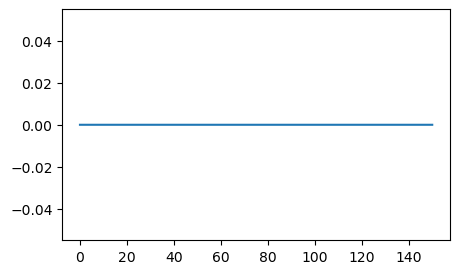

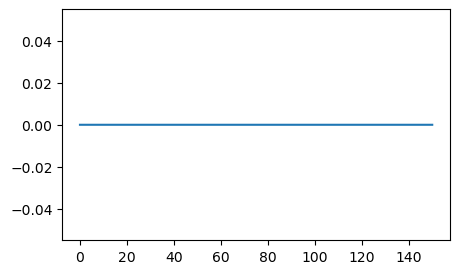

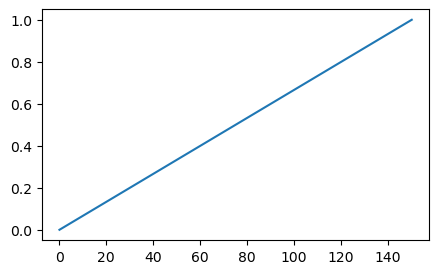

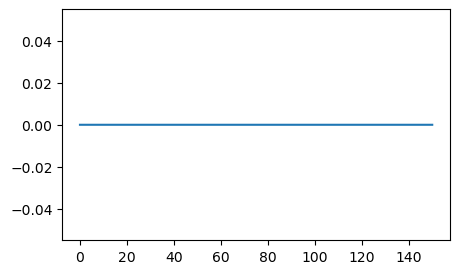

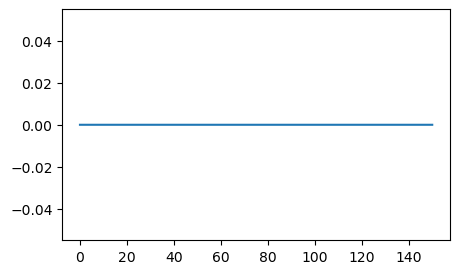

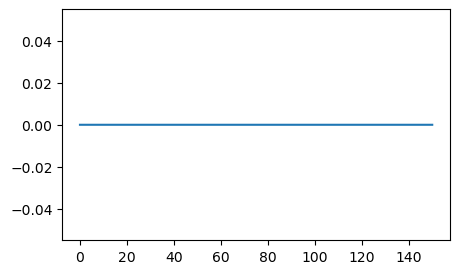

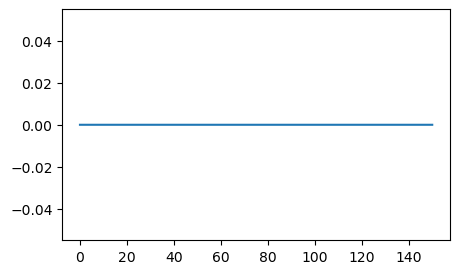

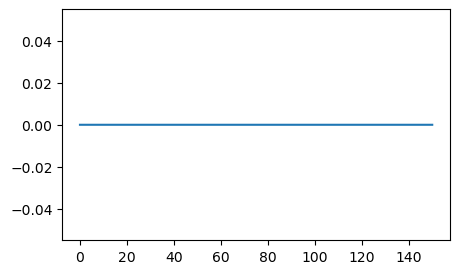

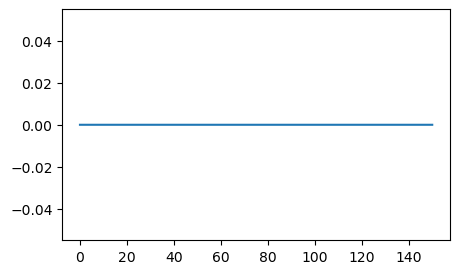

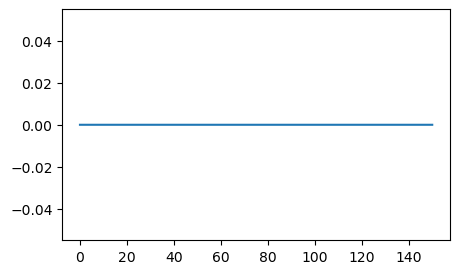

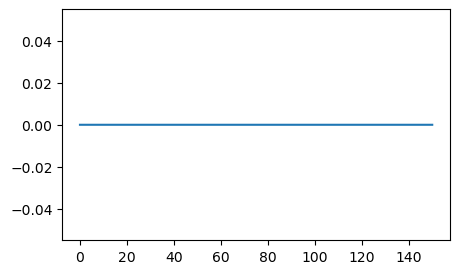

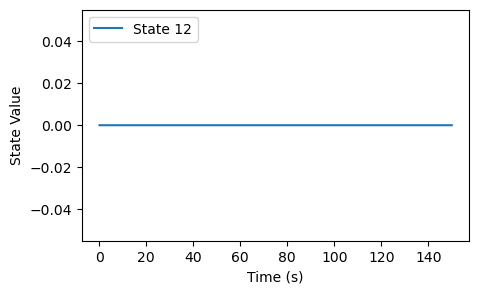

In [106]:
# Test 1: Hover 1 m above ground 

target_state = np.array([0,0,1, 0, 0, 0, 0, 0, 0, 0, 0, 0])
initial_state = np.array([0,0,0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

def get_straight_path_z(initial_state, target_state, steps): 
    z_linspace = np.linspace(initial_state[2], target_state[2], steps)
    state_hist = [] 
    time_hist = [] 
    current_time = 0.0 
    dt = 0.1
    for z_var in z_linspace: 
        state_hist.append(sp.Matrix([0,0,z_var, 0,0,0, 0,0,0,0,0,0]))
        current_time += dt
        time_hist.append(current_time)
    return state_hist, time_hist

states, times = get_straight_path_z(initial_state, target_state, 1500)
time_hist, state_hist = follow_path(states, times)

print("=" * 100)
print("Status: {achieved}")
print("=" * 100)

states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

for value in range(states_np.shape[1]):
    plt.figure(figsize=(5, 3))
    plt.plot(time_hist, states_np[:, value], label=f"State {value+1}")

plt.xlabel("Time (s)")
plt.ylabel("State Value")
plt.legend(loc="upper left")
plt.show()

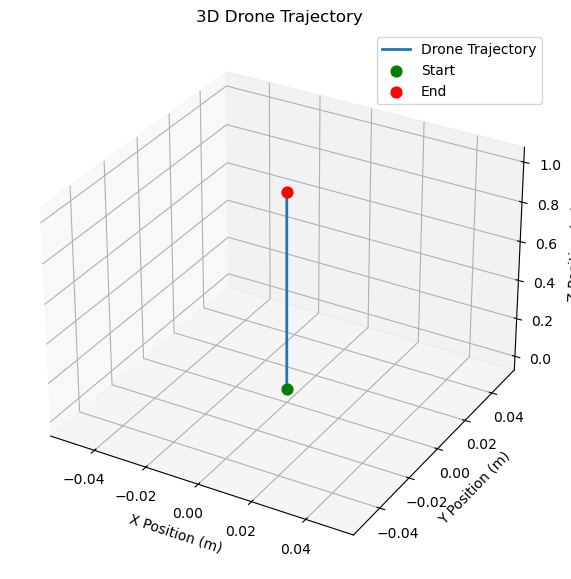

In [ ]:

states_np = np.array([np.array(s.tolist(), dtype=float).flatten()for s in state_hist])

x = states_np[:, 0]
y = states_np[:, 1]
z = states_np[:, 2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, label="Drone Trajectory", linewidth=2)

ax.scatter(x[0], y[0], z[0], color='green', s=60, label="Start")
ax.scatter(x[-1], y[-1], z[-1], color='red', s=60, label="End")

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_title("3D Drone Trajectory")

ax.legend()
plt.show()


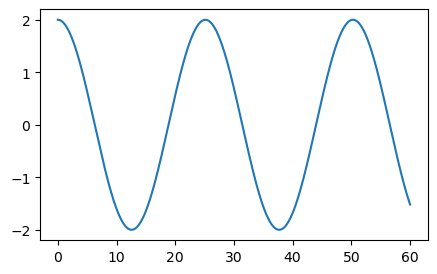

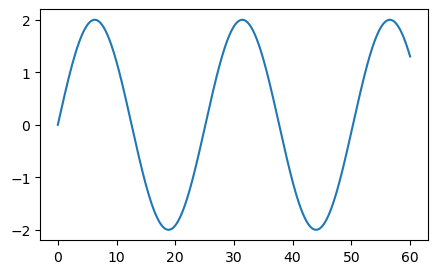

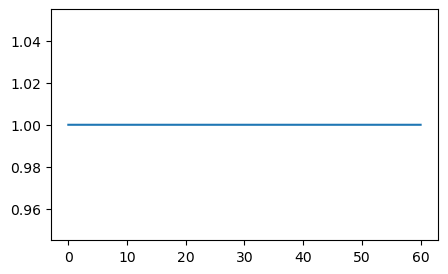

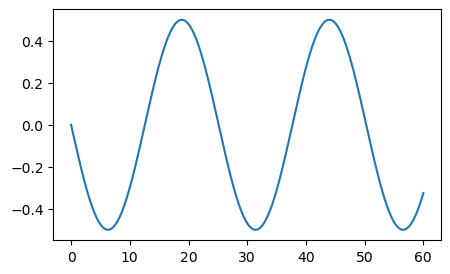

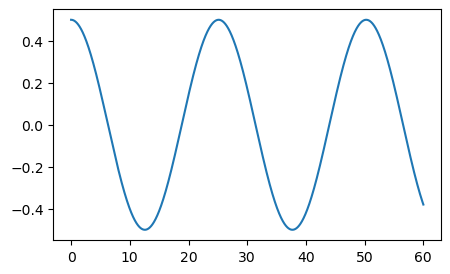

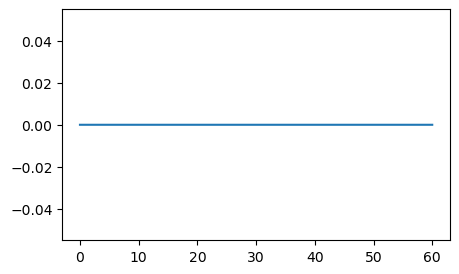

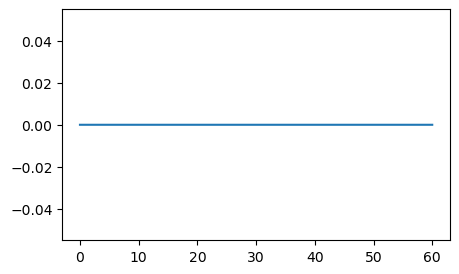

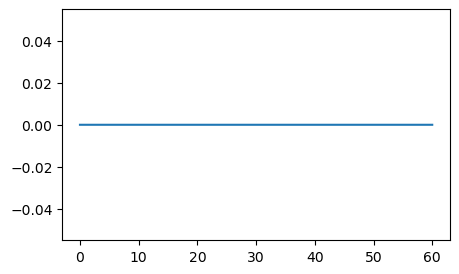

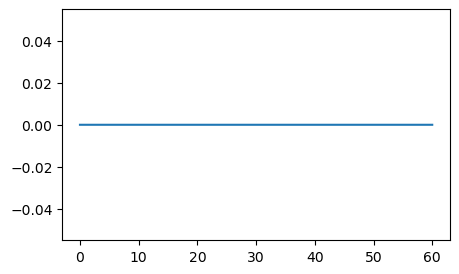

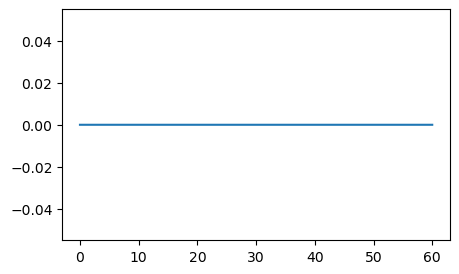

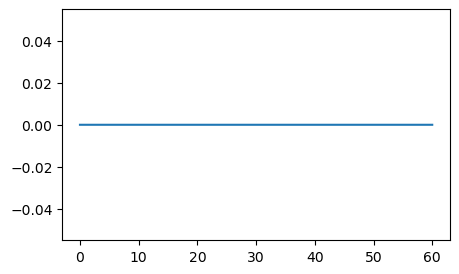

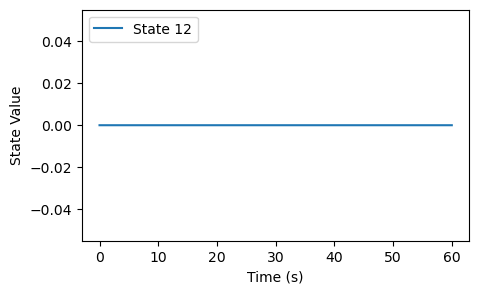

In [108]:
# Test 2: Circle

def get_circle(R, v_circ, t_0, t_f, dt):
    omega = v_circ/R
    time= list(np.linspace(t_0, t_f, int((t_f-t_0)/dt)))
    trajectory_vec = []
    for t in time: 
        x = R*np.cos(omega*t)
        y = R*np.sin(omega*t)
        z = 1
        
        vx = -R*omega*np.sin(omega*t)
        vy =  R*omega*np.cos(omega*t)
        vz = 0.0

        trj_point = sp.Matrix([x,y,z,vx,vy,vz])
        trajectory_vec.append(trj_point)
    return trajectory_vec, time

# Testing:   
states, times = get_circle(2, 0.5, 0, 60, 0.01)
time_hist, state_hist = follow_path(states, times)
states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

for value in range(states_np.shape[1]):
    plt.figure(figsize=(5, 3))
    plt.plot(time_hist, states_np[:, value], label=f"State {value+1}")

plt.xlabel("Time (s)")
plt.ylabel("State Value")
plt.legend(loc="upper left")
plt.show()

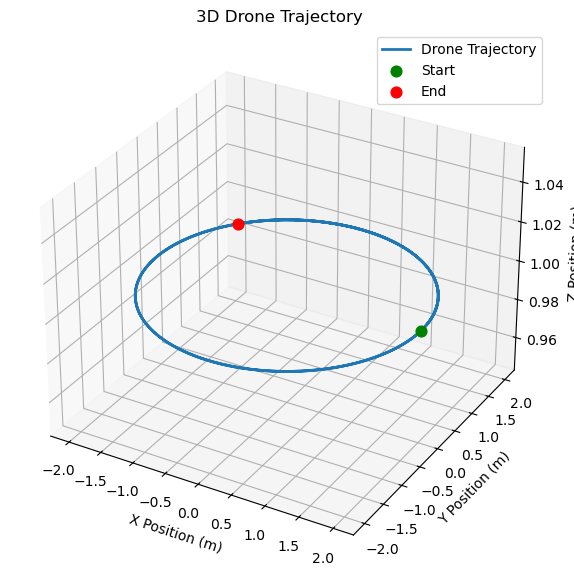

In [ ]:

# Convert state history to numpy array
states_np = np.array([np.array(s.tolist(), dtype=float).flatten()for s in state_hist])

x = states_np[:, 0]
y = states_np[:, 1]
z = states_np[:, 2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot(x, y, z, label="Drone Trajectory", linewidth=2)

ax.scatter(x[0], y[0], z[0], color='green', s=60, label="Start")
ax.scatter(x[-1], y[-1], z[-1], color='red', s=60, label="End")

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_title("3D Drone Trajectory")

ax.legend()
plt.show()


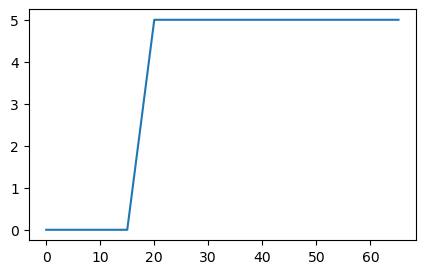

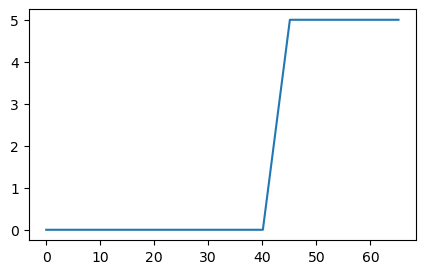

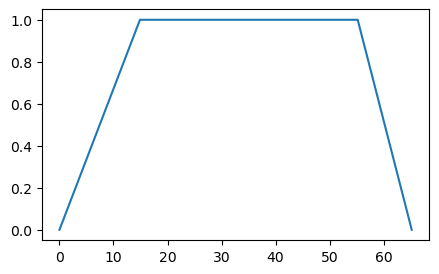

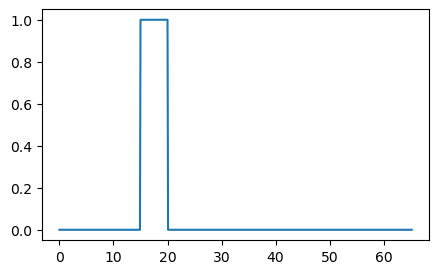

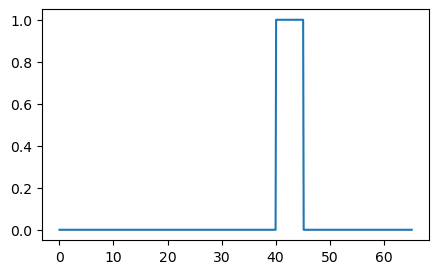

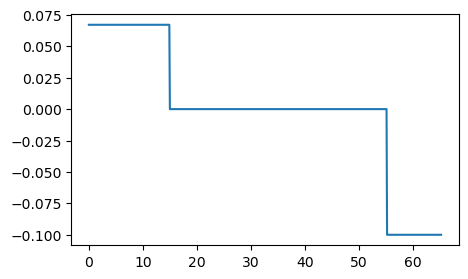

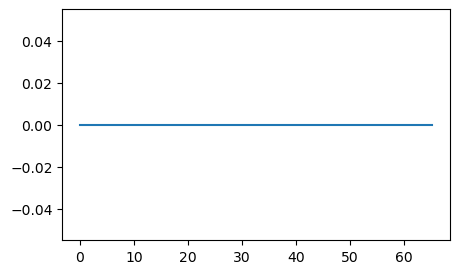

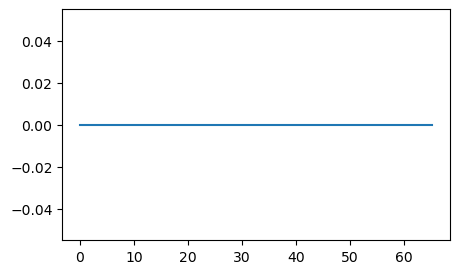

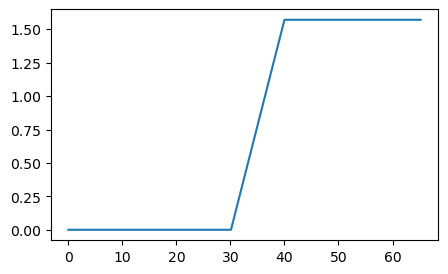

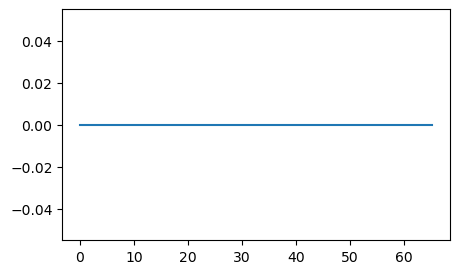

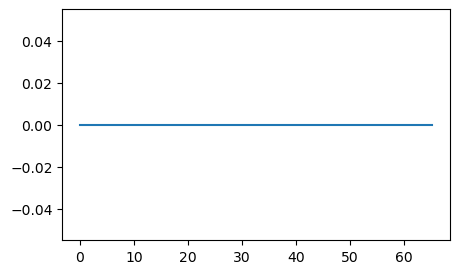

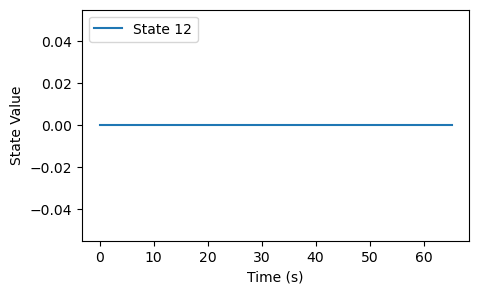

In [110]:

def get_trajectory_path():
    dt = 0.1
    step_1_time = 15
    steps = int(step_1_time/dt)

    trajectory_pts = []
    time_points = []
    current_time = 0.0

    position_points = np.linspace(0.0, 1.0, steps)
    vz = (position_points[-1] - position_points[-2])/dt

    for var in position_points:
        trajectory_pts.append(
            sp.Matrix([0, 0, var, 0, 0, vz, 0, 0, 0, 0, 0, 0])
        )
        time_points.append(current_time)
        current_time += dt

    position_points = np.linspace(0.0, 5.0, 51)

    for var in position_points:
        trajectory_pts.append(
            sp.Matrix([var, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0])
        )
        time_points.append(current_time)
        current_time += dt

    for i in range(100):
        trajectory_pts.append(sp.Matrix([5, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    yaw_points = np.linspace(0, np.pi/2, 100)

    for yaw in yaw_points:
        trajectory_pts.append(sp.Matrix([5, 0, 1, 0, 0, 0, 0, 0, yaw, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    position_points = np.linspace(0.0, 5.0, 51)

    for var in position_points:
        trajectory_pts.append(sp.Matrix([5, var, 1, 0, 1, 0, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    for i in range(100):
        trajectory_pts.append(sp.Matrix([5, 5, 1, 0, 0, 0, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    position_points = np.linspace(1.0, 0.0, 101)
    vz = (position_points[-1] - position_points[-2])/dt

    for var in position_points:
        trajectory_pts.append(sp.Matrix([5, 5, var, 0, 0, vz, 0, 0, np.pi/2, 0, 0, 0]))
        time_points.append(current_time)
        current_time += dt

    return trajectory_pts, np.array(time_points)


trajectory_pts, time_points = get_trajectory_path()


time_hist, state_hist = follow_path(trajectory_pts, time_points)
states_np = np.array([np.array(s.tolist(), dtype=float).flatten() for s in state_hist])

for value in range(states_np.shape[1]):
    plt.figure(figsize=(5, 3))
    plt.plot(time_hist, states_np[:, value], label=f"State {value+1}")

plt.xlabel("Time (s)")
plt.ylabel("State Value")
plt.legend(loc="upper left")
plt.show()

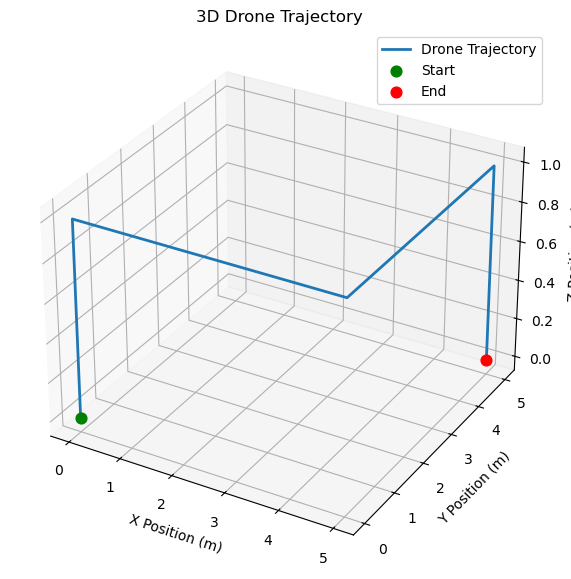

In [ ]:

states_np = np.array([np.array(s.tolist(), dtype=float).flatten()for s in state_hist])

x = states_np[:, 0]
y = states_np[:, 1]
z = states_np[:, 2]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Drone Trajectory", linewidth=2)

ax.scatter(x[0], y[0], z[0], color='green', s=60, label="Start")
ax.scatter(x[-1], y[-1], z[-1], color='red', s=60, label="End")

ax.set_xlabel("X Position (m)")
ax.set_ylabel("Y Position (m)")
ax.set_zlabel("Z Position (m)")
ax.set_title("3D Drone Trajectory")

ax.legend()
plt.show()
